# Splitting and Masking

### Merging Features and Labels

This builds off of prior notebooks, beginning with combinging the results of tessera_download.ipynb and sedona_exploration.ipynb. This was accomplished in the command line.

Begin by setting your environment:
deactivate venv if necessary
unload the course module if necessary
module load python/anaconda/py3.10-2023.03
export PROJ_DATA=/usr/local/anaconda3/2023.03/share/proj/
export PROJ_LIB=/usr/local/anaconda3/2023.03/share/proj/

Note: I wound up needing to use /usr/local/anaconda3/2023.03/share/proj/ rather than /usr/share/proj. I believe this was due to extant environment issues with my user and may not be appropriate for everyone, but I documented the difference here in case it is pertinent to others. I found this with the same `find / -name proj.db 2>/dev/null` command.

Once set, merging the features and labels into a single .tif was a single command:

`gdal_merge.py -separate -o feature_and_class.tif 2022_foco_bbox_quant.tif surface_fuels_aligned.tif`

The `-separate` flag indicates that the bands should be stacked rather than tryig to mosaic the geotiffs. This output a file with banded blocks rather than tiled and needed to be translated back to 256x256 blocks to remain consistent with prior work. `gdal_merge.py` can create the correct output initially, but this translation came in useful later.

`gdal_translate -co TILED=YES -co BLOCKXSIZE=256 -co BLOCKYSIZE=256 \
               -co COMPRESS=DEFLATE -co PREDICTOR=2 -co BIGTIFF=IF_SAFER \
               -co INTERLEAVE=PIXEL \
               data/land_use_aligned.tif data/land_use_aligned_tiled.tif`

In [67]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt

### Splitting

Splitting the initial dataset into train, validation, and test sets was done here in a deterministic checkerboard-esque pattern. Starting in the top left corner, the following pattern was tiled across the dataset, with each entry representing a 256x256 block:

`[train] [train] [train]`\
`[train] [ val ] [test ]`

This provides an even distribution across our AOI. By having the pattern block large subsets together, it also mitigates the potential for our models to simply evaluate a given pixel based on its neighbors. We can add further mitigation if we feel it necessary by removing the border pixels of each block from consideration. Our bounding box is unsurprisingly not evenly divisible by 256 so the bottom-most and right-most blocks are not fully populated meaning that our split is not a perfect split of sixths, but they are still close. Additionally, all splits are confirmed to contain all categories. An array of the same size as our geotiffs is populated with this pattern and then used for boolean indexing of our dataset to generate our subseets.

### Masking

Implementing the split in this way suggested that masking could be handled similarly. The land_use_aligned.tif is transformed to have the same block shape as our other tifs, then imported to generate the mask. The current implementation simply excludes the ambiguous and unmarked categories, but could easily be adapted to mask to any categories we see fit (potentially useful during later sensitivity analysis).


In [68]:
with rasterio.open("data/feature_and_class_tiled.tif") as src:
    data = src.read()
    profile = src.profile.copy()

X = data[:-1]
y = data[-1]

# 1 = train, 2 = validation, 3 = test
PATTERN = np.array([[1, 1, 1],
                    [1, 2, 3]], dtype="uint8")

rows, cols = y.shape
block_r = np.arange(rows) // 512
block_c = np.arange(cols) // 512
split = PATTERN[block_r[:, None] % PATTERN.shape[0],
                block_c[None, :] % PATTERN.shape[1]]

with rasterio.open("data/land_use_aligned_tiled.tif") as mask_src:
    mask_input = mask_src.read()[0]
mask = np.vectorize(lambda x: 0 if x == 0 or x == 254 else 1)(mask_input)

split = np.array(split) * mask

X_train, y_train = X[:, split == 1].T, y[split == 1]
X_val,   y_val   = X[:, split == 2].T, y[split == 2]
X_test,  y_test  = X[:, split == 3].T, y[split == 3]

# Check class coverage
for name, labels in [("train", y_train), ("val", y_val), ("test", y_test)]:
    classes, counts = np.unique(labels, return_counts=True)
    print(f"{name}: {len(labels):,} pixels, classes {dict(zip(classes.tolist(), counts.tolist()))}")

# Optional: save the split as a georeferenced mask for checking in QGIS
profile.update(count=1, dtype="uint8", nodata=0, compress="deflate")
with rasterio.open("data/split_mask.tif", "w", **profile) as dst:
    dst.write(split, 1)

train: 17,651,527 pixels, classes {99: 35773, 101: 1455741, 102: 4987955, 104: 8440, 121: 80306, 122: 5175139, 142: 52807, 144: 348640, 147: 459912, 157: 990838, 171: 563029, 182: 36, 191: 307255, 203: 1620, 255: 3184036}
val: 4,038,709 pixels, classes {99: 1733, 101: 277767, 102: 1053093, 104: 1291, 121: 3721, 122: 1130988, 142: 14899, 144: 95593, 147: 114362, 157: 244970, 171: 161130, 191: 83674, 203: 30, 255: 855458}
test: 3,610,333 pixels, classes {99: 6578, 101: 327617, 102: 1088428, 104: 460, 121: 9455, 122: 947825, 142: 10984, 144: 54090, 147: 78006, 157: 86523, 171: 70877, 183: 68, 191: 48610, 203: 2, 255: 880810}


### Results

Above we see the total amount of pixels in a given subset as well as the counts of each category. Presently this is usedd to generate a masking file which can be applied as needed to our dataset (including any future datasets). This could instead be altered to produce copies of the resultant sets, which would take more storage space but require less subsequent reprocessing. This also means loading whole files. 

One of our previously stated concerns was memory. Neither the land use tifs nor the feature and class tifs are particularly large in context of what we've been working with, and I had no issues running anything in this notebook. That may be enough on it's own. Additionally, rasterio's window method can apparently be used to only load the relevant blocks of a file at a time without needing to split this out into a set of smaller files. The same windowing technique may also prove useful for the CNN, grabbing patches rather than pixels.

Below, a visual of the full feature set is displayed for comparison with the subsequently displayed training set which has had the above mask applied.

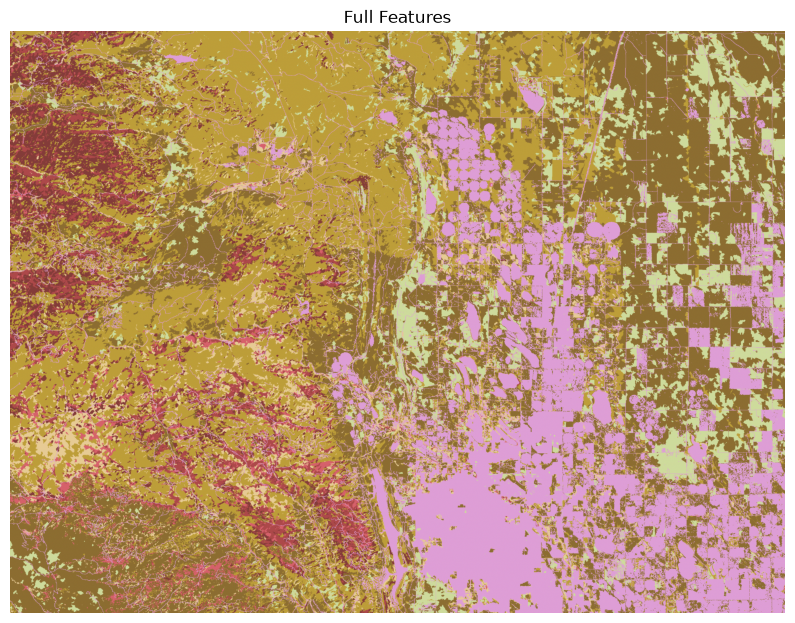

In [69]:
#just to trigger the same colorset as the following
y[0][0] = 0

plt.figure(figsize=(10, 8))
plt.imshow(y, cmap="tab20b")
plt.title("Full Features")
plt.axis("off")
plt.show()

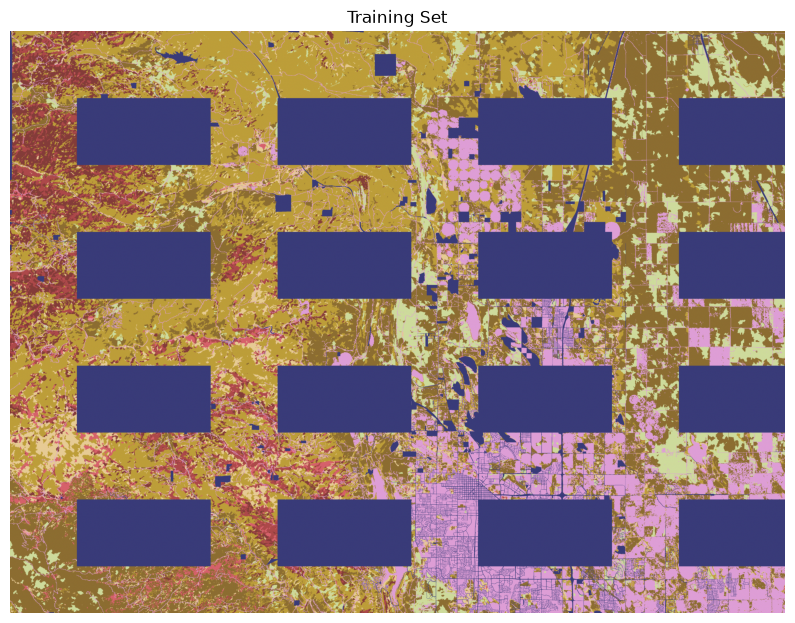

In [59]:
# y_show = np.array(y) * np.vectorize(lambda x: 0 if x == 0 or x == 254 else 1)(mask)
y_train_masked = np.array(y) * np.vectorize(lambda x: 0 if x != 1 else x)(split)
plt.figure(figsize=(10, 8))
plt.imshow(y_train_masked, cmap="tab20b")
plt.title("Training Set")
plt.axis("off")
plt.show()